# Who joined when, and what happens to each group month by month?

**Week 4, Thursday, chapter 1 of 3 (L1, counted by hand).**

> *Illustrative case: the company is real, the situation and the data are synthetic, built for
> this class.*

**The ticket. Zomato Gold, Chennai, the membership and the app's order flow.** Zomato Gold is the
food-delivery app's paid membership, whose members get free delivery (Zomato's shareholder letter of
19 May 2023, checked 12 October 2026). The membership dashboard reports month-two retention for
Chennai, the share of members two or more months past their signup month who ordered in the month,
as flat at 38 percent for June, July, August and September 2026. A member who places no order in a
month is not retained that month; she is still a member and may order again. A **cohort** is the
members who joined in the same month. Each cohort's own curve falls with age, and each cohort's
month-one rate is lower than the one before: January 58 percent, April 53, July 49, and August 31.
The August cohort, 13,000 members, 2.6 times the 5,000 a month of January to July, grew out of a
sale week with a discounted first month. On Monday 14 September 2026 a new checkout flow shipped on
Android; since then members' add-to-cart to order conversion on Android fell from 58 to 44 percent,
while members on iOS went from 57 to 56 and non-members on Android from 52 to 51. **The ask, due
Friday:** is it a cohort problem (members who joined in some months order less than members who
joined in others) or an everyone problem (members of every signup month changed at once), which
funnel stage owns the loss, and what should be fixed first, with the evidence.

**Who needs the answer.** The membership lead, who reads the dashboard every month and has to
say on Friday whether Gold has a cohort problem or an everyone problem. A wrong call sends the
fix to the wrong place.

**The questions on the way.**

1. Why can an average over two groups hide what each group did?
2. Which of the twelve members ordered in each month since they joined?
3. What does each signup group keep, month one, month two and on?
4. What does the dashboard's way of counting say about the twelve, and what does it leave out?

In [1]:
# Load the twelve members chapter 1 counts, and the full tables to prove they are real rows.
import pandas as pd
import matplotlib.pyplot as plt

def check(name, ok):
    print(("PASS  " if ok else "FAIL  ") + name)

cols = ["ordered_in_jun", "ordered_in_jul", "ordered_in_aug", "ordered_in_sep"]
twelve = pd.read_csv("../data/C2_W04_D04_twelve_rows_STUDENT.csv", dtype={c: "Int64" for c in cols})
members = pd.read_csv("../data/C2_W04_D04_members_STUDENT.csv")
member_months = pd.read_csv("../data/C2_W04_D04_member_months_STUDENT.csv")
print(f"{len(twelve)} members on the card; {len(members):,} members and "
      f"{len(member_months):,} member-months in the full tables")

12 members on the card; 53,089 members and 241,492 member-months in the full tables


## Why can an average over two groups hide what each group did?

A coaching centre (invented numbers) takes a batch of 10 in June and a batch of 10 in July. In
each batch's second month, 6 of the June batch and 4 of the July batch come back. **Predict
before you run.** What share of the 20 came back?

- a) 40 percent, the July batch's rate
- b) 50 percent, a rate that is neither batch's
- c) 60 percent, the June batch's rate
- d) It cannot be computed without the batch sizes

June batch: 6 of 10 = 60%
July batch: 4 of 10 = 40%
together: 10 of 20 = 50%


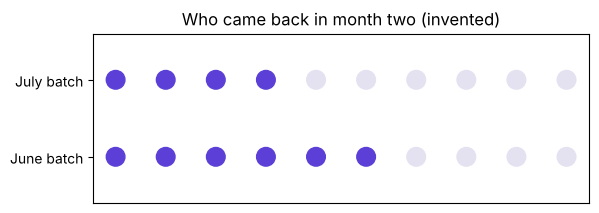

PASS  the toy: 10 of 20 came back, 50 percent


In [2]:
# The toy, counted: each batch has its own rate, and the total names neither.
back = {"June batch": (6, 10), "July batch": (4, 10)}
for name, (b, n) in back.items():
    print(f"{name}: {b} of {n} = {b / n:.0%}")
total = sum(b for b, _ in back.values()), sum(n for _, n in back.values())
print(f"together: {total[0]} of {total[1]} = {total[0] / total[1]:.0%}")
fig, ax = plt.subplots(figsize=(6.4, 2.2))
for row, (name, (b, n)) in enumerate(back.items()):
    ax.scatter(range(n), [row] * n, s=180, c=["#5B3FD6"] * b + ["#E4E1F1"] * (n - b))
ax.set_yticks([0, 1], list(back)); ax.set_xticks([]); ax.set_ylim(-0.6, 1.6)
ax.set_title("Who came back in month two (invented)"); plt.show()
check("the toy: 10 of 20 came back, 50 percent", total == (10, 20))

**What happened.** The answer is b: 10 of 20, 50 percent, which is neither batch's rate. A
single average over several groups says nothing about any one of them. The dashboard is such
an average, over Gold members who joined in different months.

## Which of the twelve members ordered in each month since they joined?

The card holds twelve members picked from the case data, which is synthetic like all of it,
to show the pattern on one page: four who joined in May, three in June and five who joined in
the August sale week on its discount. On all 53,089 members (notebook 02), May's month one is
52 percent and June's 50. A cell is 1 when the member placed at least one order that calendar
month and 0 when she placed none. A blank cell is a month before she joined, or the
month she joined, which is month zero and is never counted. **Month one** is the first full
calendar month after the signup month, so May's month one is June and August's is September.

In [3]:
# The card as the data holds it, a blank where the month is not counted for that member.
twelve.astype(object).where(twelve.notna(), "")

,member_id,signup_month,signup_channel,ordered_in_jun,ordered_in_jul,ordered_in_aug,ordered_in_sep
0,ZG20844,May,organic,1,1,1,1
1,ZG21052,May,organic,1,1,0,0
2,ZG22010,May,organic,1,0,0,0
3,ZG22634,May,organic,0,0,0,0
4,ZG25312,Jun,organic,,1,1,1
5,ZG27475,Jun,organic,,1,0,0
6,ZG28603,Jun,organic,,0,0,0
7,ZG38681,Aug,sale,,,,1
8,ZG40539,Aug,sale,,,,0
9,ZG41000,Aug,sale,,,,0


**How the next cell counts by age.** `melt` turns the card from one row per member, with a
column per month, into one row per member per month, so each row can carry its own age. Each
month gets its place among June to September: June 0, July 1, August 2, September 3. A signup
month gets a place on the same scale, so May, the month before June, is -1, June is 0 and
August is 2. Age is the month's place minus the signup month's: for a May member, June is
0 - (-1) = 1, her month one. One `pivot_table` with two functions, `sum` and `count`, then
gives two tables side by side: how many ordered at each age, and how many were counted.

**Predict before you run.** Read by months since joining rather than by calendar month, which
group keeps the largest share in its own month one?

- a) The May members
- b) The June members
- c) The August sale-week members
- d) All three keep the same share

In [4]:
# One row per member per month, and her age that month: month k is the k-th month after joining.
months = ["jun", "jul", "aug", "sep"]
joined_at = {"May": -1, "Jun": 0, "Aug": 2}      # where each signup month sits among jun to sep
long = twelve.melt(id_vars=["member_id", "signup_month", "signup_channel"],
                   var_name="month", value_name="ordered").dropna()
long["month"] = long["month"].str[-3:]
long["ordered"] = long["ordered"].astype(int)
long["age"] = long["month"].map(months.index) - long["signup_month"].map(joined_at)
by_age = long.pivot_table(index="signup_month", columns="age", values="ordered",
                          aggfunc=["sum", "count"], sort=False)
kept = by_age["sum"]
check("May keeps 3, 2, 1, 1 of 4", list(kept.loc["May", [1, 2, 3, 4]]) == [3, 2, 1, 1])
check("June keeps 2, 1, 1 of 3", list(kept.loc["Jun", [1, 2, 3]]) == [2, 1, 1])
check("August keeps 1 of 5 in month one", kept.loc["Aug", 1] == 1)
full = member_months.assign(ordered=member_months["orders"].gt(0).astype(int),
                            month=member_months["month"].map({"2026-06": "jun", "2026-07": "jul",
                                                              "2026-08": "aug", "2026-09": "sep"}))
same = long.merge(full, on=["member_id", "month"], suffixes=("_card", "_data"))
check("every card cell is the member's real month in member_months",
      len(same) == len(long) and (same["ordered_card"] == same["ordered_data"]).all())
shown = by_age["sum"].astype("Int64").astype(str) + " of " + by_age["count"].astype("Int64").astype(str)
shown.where(by_age["count"].notna(), "").rename(columns={k: f"month {k}" for k in shown.columns})

PASS  May keeps 3, 2, 1, 1 of 4
PASS  June keeps 2, 1, 1 of 3
PASS  August keeps 1 of 5 in month one


PASS  every card cell is the member's real month in member_months


age,month 1,month 2,month 3,month 4
signup_month,,,,
May,3 of 4,2 of 4,1 of 4,1 of 4
Jun,2 of 3,1 of 3,1 of 3,
Aug,1 of 5,,,


**What happened.** The answer is a. The May members kept 3 of 4 in month one, the June members
2 of 3 and the August sale-week members 1 of 5. Each group falls as it ages: May runs 3, 2, 1,
1 of 4, and June runs 2, 1, 1 of 3. Each later group also starts lower. Fixing the entry
moment, the month a member joined, is what lets the three be compared at all.

## What does the dashboard's way of counting say about the twelve, and what does it leave out?

The dashboard counts a member from her second month after joining: in each reporting month, it
takes every member two or more months past her signup month and asks what share ordered. **Predict
before you run.** On the twelve, what does the dashboard's way read in August and in September?

- a) It falls from August to September, because the sale-week members ordered so little
- b) It reads 2 of 7 in both months, and the five sale-week members are not in it
- c) It rises, because the sale-week members are new
- d) It reads 3 of 12 in both months

In [5]:
# Each reporting month counted two ways: from month two on (the dashboard), and everyone.
ways = {}
for m in ["jul", "aug", "sep"]:
    dash = long[(long["month"] == m) & (long["age"] >= 2)]
    every = long[(long["month"] == m) & (long["age"] >= 1)]
    ways[m] = {"dashboard, month two on": f'{dash["ordered"].sum()} of {len(dash)}',
               "everyone who joined before": f'{every["ordered"].sum()} of {len(every)}'}
pd.DataFrame(ways)

,jul,aug,sep
"dashboard, month two on",2 of 4,2 of 7,2 of 7
everyone who joined before,4 of 7,2 of 7,3 of 12


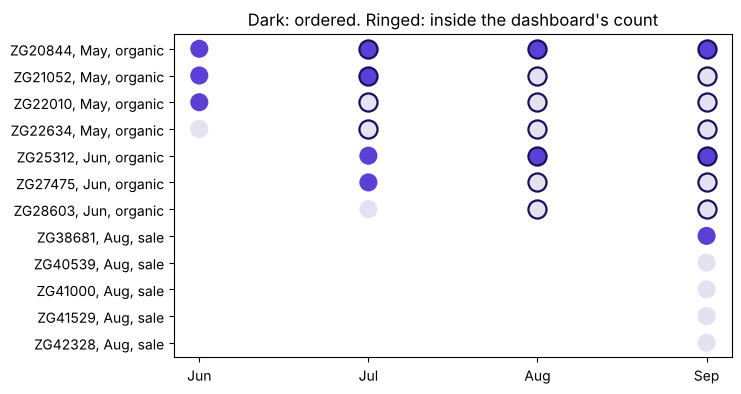

PASS  the dashboard's way reads 2 of 7 in August and in September
PASS  everyone who joined before September: 3 of 12 ordered


In [6]:
# The card drawn: dark when she ordered, ringed when the dashboard counts her that month.
fig, ax = plt.subplots(figsize=(7.2, 4.2))
rows = {mid: i for i, mid in enumerate(twelve["member_id"])}
for _, r in long.iterrows():
    ax.scatter(months.index(r["month"]), -rows[r["member_id"]], s=170,
               c="#5B3FD6" if r["ordered"] == 1 else "#E4E1F1",
               edgecolors="#1A0F5C" if r["age"] >= 2 else "none", linewidths=1.6)
ax.set_xticks(range(4), ["Jun", "Jul", "Aug", "Sep"])
ax.set_yticks([-i for i in range(len(twelve))],
              [f"{mid}, {m}, {ch}" for mid, m, ch in
               zip(twelve["member_id"], twelve["signup_month"], twelve["signup_channel"])])
ax.set_title("Dark: ordered. Ringed: inside the dashboard's count"); plt.show()
check("the dashboard's way reads 2 of 7 in August and in September",
      ways["aug"]["dashboard, month two on"] == ways["sep"]["dashboard, month two on"] == "2 of 7")
check("everyone who joined before September: 3 of 12 ordered", ways["sep"]["everyone who joined before"] == "3 of 12")

**What happened.** The answer is b. Counted the dashboard's way, 2 of 7 members ordered in
August and 2 of 7 in September: the number did not move, though five new members arrived and
four of them did not order. They are outside the count until their second month, October.
Counting everyone who joined before September gives 3 of 12. On the full data, chapter 2
finds the same two readings: 38 percent the dashboard's way, 36 counting everyone.

## Why does a big new group keep an average flat while the old group shrinks?

A second toy (invented). Last month batch A had 100 members and 50 came: 50 percent. This
month batch A falls to 40 of 100, and a new batch B of 400 joins with 210 coming, 52.5 percent.
The **blend** is the one rate over every batch together. **Predict before you run:** does the
blend rise, fall or hold?

last month 50%, this month 50%, weighted average 50%


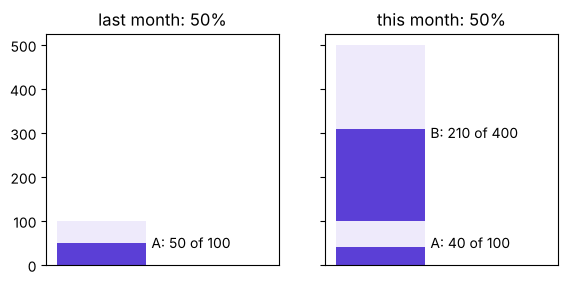

PASS  the blend holds at 50 percent while batch A falls
PASS  the blend equals the size-weighted average of the batch rates


In [7]:
# The blend as a size-weighted average: a big young batch holds it up while batch A falls.
last = {"A": (50, 100)}
now = {"A": (40, 100), "B": (210, 400)}
last_rate = sum(c for c, _ in last.values()) / sum(n for _, n in last.values())
now_rate = sum(c for c, _ in now.values()) / sum(n for _, n in now.values())
weighted = sum(n * (c / n) for c, n in now.values()) / sum(n for _, n in now.values())
print(f"last month {last_rate:.0%}, this month {now_rate:.0%}, weighted average {weighted:.0%}")
fig, axes = plt.subplots(1, 2, figsize=(6.6, 3.0), sharey=True)
for ax, (title, d) in zip(axes, [("last month", last), ("this month", now)]):
    bottom = 0
    for name, (c, n) in d.items():
        ax.bar(0, c, bottom=bottom, color="#5B3FD6"); ax.bar(0, n - c, bottom=bottom + c, color="#EEEAFB")
        ax.text(0.45, bottom + n / 2, f"{name}: {c} of {n}", va="center"); bottom += n
    ax.set_title(f"{title}: {bottom and sum(c for c, _ in d.values()) / bottom:.0%}")
    ax.set_xlim(-0.5, 1.6); ax.set_xticks([])
plt.show()
check("the blend holds at 50 percent while batch A falls", last_rate == now_rate == 0.5)
check("the blend equals the size-weighted average of the batch rates", abs(weighted - now_rate) < 1e-12)

**What happened.** It holds at 50 percent: 250 of 500, while batch A fell from 50 to 40
percent. A blend is an average weighted by size, so a large group arriving at a high early rate
props it up. Next month batch B ages too, and unless another large batch joins, the blend
starts to fall. On the Gold dashboard the prop is gentler: each month one new cohort of about
5,000 enters the count at about 38.5 percent, a little above the older cohorts' slow slide.
Notebook 02 shows it.

**The questions, answered.** (1) An average over two groups is neither group's number: 10 of
20 hid a 60 and a 40. (2) The card shows who ordered each month; blanks are months before or at
joining. (3) May kept 3, 2, 1, 1 of 4, June 2, 1, 1 of 3, and the August sale week 1 of 5 in
month one. (4) The dashboard's way read 2 of 7 in August and in September, with the five
sale-week members outside its count.